# Assignment 3 - Fashion-MNIST Classification

The objective with this assignment is to build and compare simple neural networks, and to explain how they are trained and evaluated. I will focus on **understanding the concepts introduced in the lectures** rather than achieving the highest accuracy.

### Importing necessary libraries

In [38]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay



### Loading and preparing Fashion-MNIST

In [39]:
# Load Fashion-MNIST 
(X_train, y_train), (X_test, y_test) = ( 
    tf.keras.datasets.fashion_mnist.load_data() 
) 
 
# Normalize pixel values to [0, 1] 
X_train = X_train.astype("float32") / 255.0 
X_test = X_test.astype("float32") / 255.0 
 
# Flatten 28 x 28 images into 784 features 
X_train = X_train.reshape(-1, 784) 
X_test = X_test.reshape(-1, 784) 
 
# Next step: 
# Split the training data into training and validation subsets. 
# Keep the test data separate for final evaluation.

## Part A — Build and compare neural networks 

### Splitting training data into training and validation subsets

In [40]:
# For reproducibility(also: lucky number <3)
tf.keras.utils.set_random_seed(13)


# Creating a train-validation split so that it is the same for all models
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size = 0.2, random_state = 13, stratify = y_train
)
# X training = 48k, X validation = 12k, X test = 10k
print(X_tr.shape, X_val.shape, X_test.shape)

(48000, 784) (12000, 784) (10000, 784)


### Creating function for building and training models 

In [41]:
def build_and_train(neurons, activation, optimizer):
    model = tf.keras.Sequential([
        tf.keras.Input(shape = (784, )),
        tf.keras.layers.Dense(neurons, activation = activation),
        tf.keras.layers.Dense(10, activation = 'softmax'),
    ])
    model.compile(
        optimizer = optimizer,
        loss = 'sparse_categorical_crossentropy',
        metrics = ['accuracy'],
    )
    history = model.fit(
        X_tr, y_tr,
        validation_data = (X_val, y_val),
        epochs = 10, batch_size = 64, verbose = 0,
    )
    return model, history


### Runnung experiments using function for building and training models

In [42]:
experiments = {
    'Baseline': (32, 'relu', 'adam'),
    'Experiment 1': (64, 'relu', 'adam'),
    'Experiment 2': (32, 'tanh', 'adam'),
    'Experiment 3': (32, 'relu', 'sgd'),
}

models, rows = {}, []
for name, (n, act, opt) in experiments.items():
    model, hist = build_and_train(n, act, opt)
    models[name] = model
    rows.append({
        'Model': name, 'Hidden neurons': n, 'Activation': act, 'Optimizer': opt,
        'Train accuracy': hist.history['accuracy'][-1],
        'Val accuracy': hist.history['val_accuracy'][-1],
    })

results = pd.DataFrame(rows)
results


,Model,Hidden neurons,Activation,Optimizer,Train accuracy,Val accuracy
0,Baseline,32,relu,adam,0.886583,0.877583
1,Experiment 1,64,relu,adam,0.900542,0.882417
2,Experiment 2,32,tanh,adam,0.893792,0.876000
3,Experiment 3,32,relu,sgd,0.846438,0.836083


### Choosing best model by validation

In [43]:
best_name = results.loc[results['Val accuracy'].idxmax(), 'Model']
best_model = models[best_name]
print('Best model: ', best_name)

test_loss, test_acc = best_model.evaluate(X_test, y_test, verbose = 0)
print(f'Test accuracy: {test_acc:.4f}')


Best model:  Experiment 1
Test accuracy: 0.8668


## Part B — Explain your neural network

### Q1. Architecture and parameters

*For the baseline model (784 inputs, 32 hidden neurons and 10 outputs), 
calculate the number of trainable weights and biases. Explain the difference between a parameter and a hyperparameter.*

(784 pixels x 32 hidden neurons) + (1 bias x 32 hidden neurons) = 25 120
(10 outputs x 32 hidden neurons) + (1 bias x 10 outputs) = 330

25 120 + 330 = 25 450


Parameters are learned during training via the connection weights and neuron biases, while hyperparameters are chosen and tested by the creator of the neural network before running it.

### Q2. Activation and loss

*Why do we use ReLU in the hidden layer and softmax in the output layer? Why is sparse categorical cross-entropy appropriate for this dataset?*

ReLU is used in the hidden layer because it adds non-linearity, which lets the network learn more than straight-line patterns, and it is fast to compute. 

Softmax is used in the output layer because it turns the 10 output scores into probabilities that sum to 1, so we can pick the most likely clothing category. 

Sparse categorical cross-entropy is appropriate because this is a multi-class problem (10 categories) and the labels are plain integers (0-9), not one-hot vectors. It gives a high loss when the model is confident but wrong.

### Q3. Training and Keras functions

*Explain the purposes of model.compile(), model.fit(), model.evaluate() and model.predict(). Briefly explain what backpropagation and the optimizer do during training.*

model.compile() sets up the training: the optimizer, the loss function and the metrics to track.

model.fit() trains the model on the training data, and can report validation performance after each epoch.

model.evaluate() calculates the loss and accuracy on a dataset (the test set).

model.predict() returns the predicted class probabilities for new data, without calculating accuracy.

Backpropagation calculates how much each weight and bias contributed to the error (the gradients). The optimizer then uses these gradients to adjust the weights and biases a little, so the loss decreases over time.


### Q4. Interpreting your experiments

*Which model achieved the highest validation accuracy? Did changing the number of neurons, activation function or optimizer always improve accuracy? Explain using your results.*

Experiment 1 achieved the highest validation accuracy (88,24%).
- Changing from 32 to 64 neurons improved accuracy (87,76% vs 88,24% for the baseline).
- Changing from ReLU to tanh did not improve accuracy (87,76% vs 87,60%).
- Changing from Adam to SGD did not improve accuracy (87,76% vs 83,60%).

So changing a setting did not always improve accuracy. SGD, for one, was worse, maybe because with default settings it learns more slowly than Adam in only 10 epochs.

## Part C — Understand classification errors

### Confusion matrix

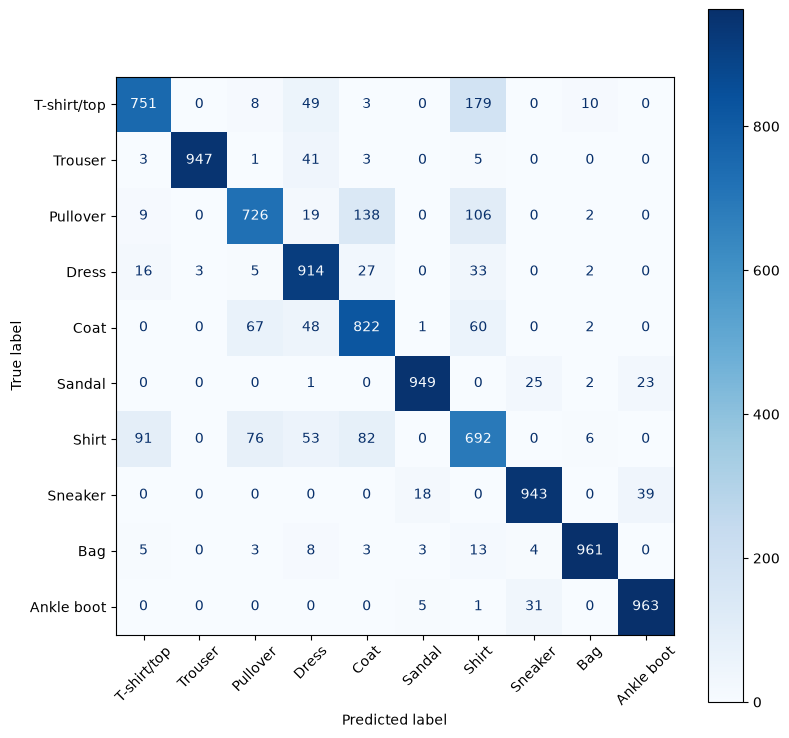

In [44]:
# the label description is found on website https://www.kaggle.com/datasets/zalando-research/fashionmnist
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

y_pred = np.argmax(best_model.predict(X_test, verbose=0), axis=1)
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation=45, cmap="Blues")
plt.show()

### Finding most often confused pair

In [45]:
off = cm.copy()
np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)
print(f"Most often confused: true label: '{class_names[i]}' -> predicted label: '{class_names[j]}' ({off[i, j]} times)")

Most often confused: true label: 'T-shirt/top' -> predicted label: 'Shirt' (179 times)


The model most often confuses **T-shirt/top and Shirt** (179 T-shirts were predicted as Shirt, and 91 Shirts as T-shirt/top). Overall accuracy gives only one number for the whole model, so it hides that some classes are predicted almost perfectly (Ankle boot 963/1000, Bag 961/1000, Sandal 949/1000) while others are much weaker (Shirt only 692/1000). The confusion matrix shows *which* classes the model gets wrong and *what it mistakes them for*, which reveals systematic errors between visually similar items (like Shirt, T-shirt/top, Pullover and Coat) that a single accuracy score averages away.